### Imports

In [1]:
import pandas as pd
import json
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, auc

### Loading data

In [2]:
labels = pd.read_csv("shared/labels.csv", index_col="row_id")

X_train = pd.read_csv("shared/X_train.csv", index_col="row_id")
y_train = labels.loc[X_train.index, "Target"]
print(X_train.shape, y_train.shape)

X_val = pd.read_csv("shared/X_val.csv", index_col="row_id")
y_val = labels.loc[X_val.index, "Target"]

print(X_val.shape, y_val.shape)

X_test = pd.read_csv("shared/X_test.csv", index_col="row_id")
y_test = labels.loc[X_test.index, "Target"]

print(X_test.shape, y_test.shape)

(2653, 11) (2653,)
(883, 11) (883,)
(888, 11) (888,)


### Data Checks

In [3]:
#checking if the split column in the labels dataframe matches the training data
print(labels.loc[X_train.index, "split"].value_counts(dropna=False))

#checking if the order of the features in the data match the selected features
with open("shared/selected_features.json", encoding="utf-8") as file:
    features = json.load(file)["features"]

print(X_train.columns.tolist() == features)

print(X_val.columns.tolist() == features)
print(X_test.columns.tolist() == features)

#checking if each id appears only once across the splits
all_ids = X_train.index.append([X_val.index, X_test.index])
print(all_ids.is_unique)

#checking if the split column in the labels dataframe matches the validation and test data
print(labels.loc[X_val.index, "split"].value_counts(dropna=False))
print(labels.loc[X_test.index, "split"].value_counts(dropna=False))

#checking the distribution of the target variable in the data
print("Train\n", y_train.value_counts(dropna=False))
print("Validation\n", y_val.value_counts(dropna=False))
print("Test\n", y_test.value_counts(dropna=False))

#checking if all the splits contain valide values
for name, table in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    values = table.to_numpy()
    print(name, np.isfinite(values).all())

split
train    2653
Name: count, dtype: int64
True
True
True
True
split
val    883
Name: count, dtype: int64
split
test    888
Name: count, dtype: int64
Train
 Target
Graduate    1325
Dropout      852
Enrolled     476
Name: count, dtype: int64
Validation
 Target
Graduate    441
Dropout     284
Enrolled    158
Name: count, dtype: int64
Test
 Target
Graduate    443
Dropout     285
Enrolled    160
Name: count, dtype: int64
Train True
Validation True
Test True


### Standarisation

In [4]:
#fitting the scaler from the training set
scaler = StandardScaler()
scaler.fit(X_train)

#standardizing the data using the fitted scaler
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

### Régression logistique

In [5]:
#fitting the logistic regression model
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_scaled, y_train)

#predicting on the validation set
y_val_pred_logreg = logreg.predict(X_val_scaled)

#calculating the macro F1 score for the logistic regression model
logreg_val_f1 = f1_score(y_val, y_val_pred_logreg, average="macro")

print("Validation macro F1:", logreg_val_f1)

Validation macro F1: 0.6561704675824364


### SVM linéaire

In [6]:
#fitting the SVM model with linear kernel
svm_linear = SVC(kernel="linear", C=1.0)
svm_linear.fit(X_train_scaled, y_train)

#predicting on the validation set
y_val_pred_linear = svm_linear.predict(X_val_scaled)

#calculating the macro F1 score for the linear SVM model
svm_linear_val_f1 = f1_score(y_val, y_val_pred_linear, average="macro")

print("Linear SVM validation macro F1:", svm_linear_val_f1)

Linear SVM validation macro F1: 0.6626394929208161


### SVM à noyau RBF

In [7]:
#fitting the SVM model with RBF kernel
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale")
svm_rbf.fit(X_train_scaled, y_train)

#predicting on the validation set
y_val_pred_rbf = svm_rbf.predict(X_val_scaled)

#calculating the macro F1 score for the RBF SVM model
svm_rbf_val_f1 = f1_score(y_val, y_val_pred_rbf, average="macro")

print("RBF SVM validation macro F1:", svm_rbf_val_f1)

RBF SVM validation macro F1: 0.6656991853031456


### Réglage de gamma

In [8]:
#testing different values of gamma for the RBF kernel
rbf_gamma_scores = {"scale": svm_rbf_val_f1}

for gamma in [0.01, 1.0]:
    model = SVC(kernel="rbf", C=1.0, gamma=gamma)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_val_scaled)
    rbf_gamma_scores[gamma] = f1_score(y_val, predictions, average="macro")

print(rbf_gamma_scores)

{'scale': 0.6656991853031456, 0.01: 0.6508231236422871, 1.0: 0.6688151649320401}


### Réglage de C pour RBF SVM

In [9]:
#testing different values of C for the RBF kernel with gamma=1.0
rbf_c_scores = {1.0: rbf_gamma_scores[1.0]}

for c_value in [0.1, 10.0]:
    model = SVC(kernel="rbf", C=c_value, gamma=1.0)
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_val_scaled)
    rbf_c_scores[c_value] = f1_score(y_val, predictions, average="macro")

print(rbf_c_scores)

{1.0: 0.6688151649320401, 0.1: 0.5105291455276412, 10.0: 0.6230408399837055}


### Réglage de C pour SVM lineaire

In [10]:
#testing different values of C for the linear kernel
linear_c_scores = {1.0: svm_linear_val_f1}

for c_value in [0.1, 10.0]:
    model = SVC(kernel="linear", C=c_value)
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_val_scaled)
    linear_c_scores[c_value] = f1_score(y_val, predictions, average="macro")

print(linear_c_scores)

{1.0: 0.6626394929208161, 0.1: 0.6539011848871005, 10.0: 0.6656954554345945}


### Réglage de C de la régression logistique

In [11]:
#testing different values of C for the logistic regression model
logreg_c_scores = {1.0: logreg_val_f1}

for c_value in [0.1, 10.0]:
    model = LogisticRegression(C=c_value, max_iter=1000)
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_val_scaled)
    logreg_c_scores[c_value] = f1_score(y_val, predictions, average="macro")

print(logreg_c_scores)

{1.0: 0.6561704675824364, 0.1: 0.6550806861177596, 10.0: 0.6592689866289241}


### Pondération des classes pour regression logistique

In [12]:
#testing the logistic regression model with class weights to handle class imbalance
logreg_balanced = LogisticRegression(
    C=10.0, max_iter=1000, class_weight="balanced"
)
logreg_balanced.fit(X_train_scaled, y_train)

predictions = logreg_balanced.predict(X_val_scaled)
logreg_balanced_val_f1 = f1_score(y_val, predictions, average="macro")

print("Unweighted:", logreg_c_scores[10.0]) #10 beause it was the best value of C in the previous test
print("Balanced:", logreg_balanced_val_f1)

Unweighted: 0.6592689866289241
Balanced: 0.6770124947371542


### Pondération du SVM linéaire

In [13]:
#testing the linear SVM model with class weights to handle class imbalance
svm_linear_balanced = SVC(kernel="linear", C=10.0, class_weight="balanced")
svm_linear_balanced.fit(X_train_scaled, y_train)

predictions = svm_linear_balanced.predict(X_val_scaled)
svm_linear_balanced_val_f1 = f1_score(y_val, predictions, average="macro")

print("Unweighted:", linear_c_scores[10.0])
print("Balanced:", svm_linear_balanced_val_f1)

Unweighted: 0.6656954554345945
Balanced: 0.6849080026309194


### Pondération du SVM RBF

In [14]:
#testing the RBF SVM model with class weights to handle class imbalance
svm_rbf_balanced = SVC(
    kernel="rbf", C=1.0, gamma=1.0, class_weight="balanced"
)
svm_rbf_balanced.fit(X_train_scaled, y_train)

predictions = svm_rbf_balanced.predict(X_val_scaled)
svm_rbf_balanced_val_f1 = f1_score(y_val, predictions, average="macro")

print("Unweighted:", rbf_c_scores[1.0])
print("Balanced:", svm_rbf_balanced_val_f1)

Unweighted: 0.6688151649320401
Balanced: 0.6437588449197547


### Évaluation sur le jeu de test

In [15]:
#fitting the unweighted RBF SVM
svm_rbf_final = SVC(kernel="rbf", C=1.0, gamma=1.0)
svm_rbf_final.fit(X_train_scaled, y_train)

#predicting on the test set
y_test_pred_logreg = logreg_balanced.predict(X_test_scaled)
y_test_pred_linear = svm_linear_balanced.predict(X_test_scaled)
y_test_pred_rbf = svm_rbf_final.predict(X_test_scaled)

#calculating the macro and weighted F1 scores
for name, predictions in [
    ("Logistic regression", y_test_pred_logreg),
    ("Linear SVM", y_test_pred_linear),
    ("RBF SVM", y_test_pred_rbf),
]:
    print(name)
    print("Test macro F1:", f1_score(y_test, predictions, average="macro"))
    print("Test weighted F1:", f1_score(y_test, predictions, average="weighted"),"\n")

Logistic regression
Test macro F1: 0.7068637331939057
Test weighted F1: 0.7616956949795145 

Linear SVM
Test macro F1: 0.6958147244964925
Test weighted F1: 0.7513261976614674 

RBF SVM
Test macro F1: 0.6456294440457814
Test weighted F1: 0.7260102195823208 



### Matrices de confusion

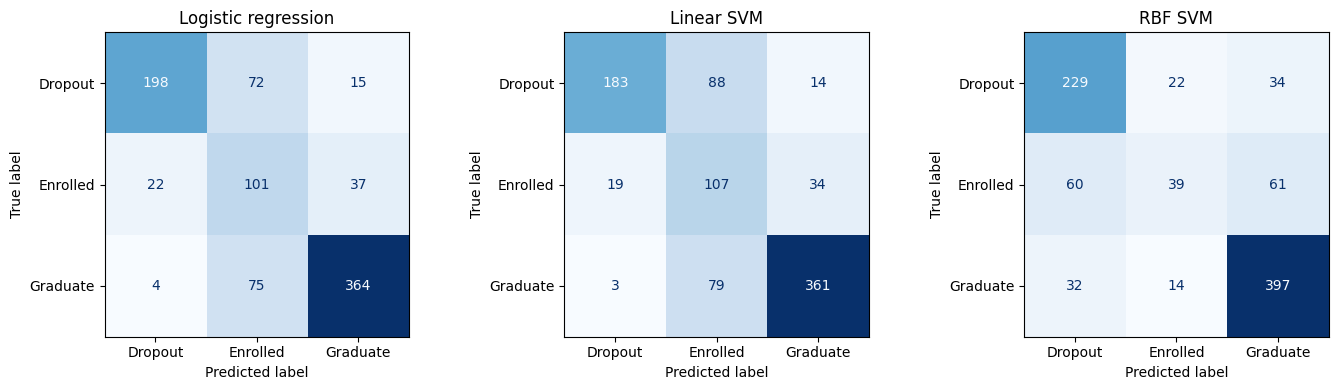

In [16]:
class_names = ["Dropout", "Enrolled", "Graduate"]
fig_confusion, axes = plt.subplots(1, 3, figsize=(14, 4))

#plotting a confusion matrix for each model
for name, predictions, ax in [
    ("Logistic regression", y_test_pred_logreg, axes[0]),
    ("Linear SVM", y_test_pred_linear, axes[1]),
    ("RBF SVM", y_test_pred_rbf, axes[2]),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=class_names,
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

### Rapport de classification

In [17]:
#calculating the classification report for each model
for name, predictions in [
    ("Logistic regression", y_test_pred_logreg),
    ("Linear SVM", y_test_pred_linear),
    ("RBF SVM", y_test_pred_rbf),
]:
    print(name)
    report = classification_report(
        y_test, predictions, labels=class_names, digits=3
    )
    print(report)

Logistic regression
              precision    recall  f1-score   support

     Dropout      0.884     0.695     0.778       285
    Enrolled      0.407     0.631     0.495       160
    Graduate      0.875     0.822     0.847       443

    accuracy                          0.747       888
   macro avg      0.722     0.716     0.707       888
weighted avg      0.794     0.747     0.762       888

Linear SVM
              precision    recall  f1-score   support

     Dropout      0.893     0.642     0.747       285
    Enrolled      0.391     0.669     0.493       160
    Graduate      0.883     0.815     0.847       443

    accuracy                          0.733       888
   macro avg      0.722     0.709     0.696       888
weighted avg      0.797     0.733     0.751       888

RBF SVM
              precision    recall  f1-score   support

     Dropout      0.713     0.804     0.756       285
    Enrolled      0.520     0.244     0.332       160
    Graduate      0.807     0.896   

### Préparer les scores pour les courbes ROC

In [18]:
# getting one score per student and per class
y_test_scores_logreg = logreg_balanced.predict_proba(X_test_scaled)
y_test_scores_linear = svm_linear_balanced.decision_function(X_test_scaled)
y_test_scores_rbf = svm_rbf_final.decision_function(X_test_scaled)

# checking the shape and class order for each model
print("Logistic regression:", y_test_scores_logreg.shape, logreg_balanced.classes_)
print("Linear SVM:", y_test_scores_linear.shape, svm_linear_balanced.classes_)
print("RBF SVM:", y_test_scores_rbf.shape, svm_rbf_final.classes_)

Logistic regression: (888, 3) ['Dropout' 'Enrolled' 'Graduate']
Linear SVM: (888, 3) ['Dropout' 'Enrolled' 'Graduate']
RBF SVM: (888, 3) ['Dropout' 'Enrolled' 'Graduate']


### Comparaison des courbes ROC entre les differentes classes et models

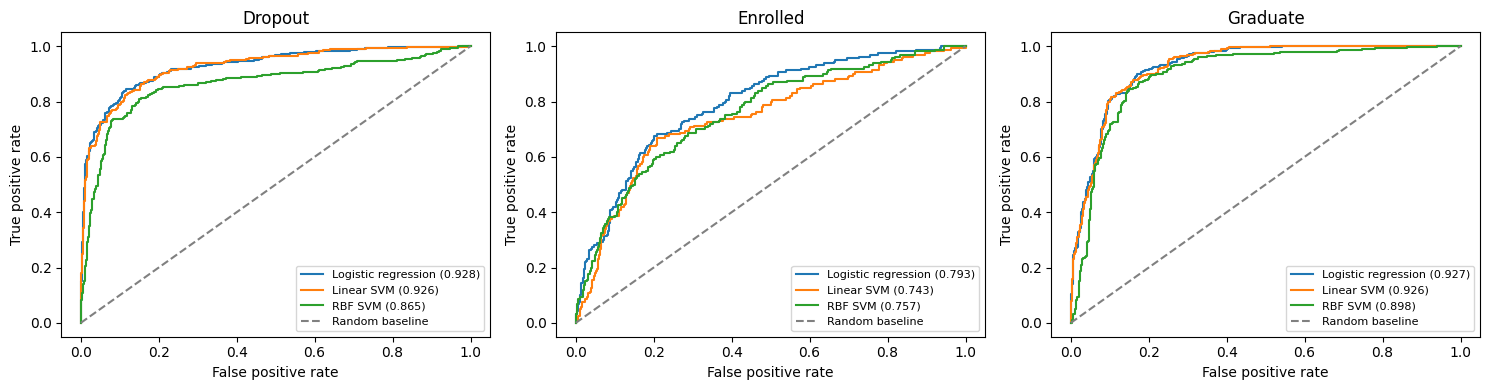

In [19]:
#initializing a list of models and their corresponding scores
models_and_scores = [
    ("Logistic regression", logreg_balanced, y_test_scores_logreg),
    ("Linear SVM", svm_linear_balanced, y_test_scores_linear),
    ("RBF SVM", svm_rbf_final, y_test_scores_rbf),
]

fig_roc, axes = plt.subplots(1, 3, figsize=(15, 4))

#plotting the ROC curve for each class and each model
for class_name, ax in zip(class_names, axes):
    y_test_binary = y_test == class_name

    for model_name, model, scores in models_and_scores:
        column = list(model.classes_).index(class_name)
        class_scores = scores[:, column]

        fpr, tpr, _ = roc_curve(y_test_binary, class_scores)
        class_auc = auc(fpr, tpr)

        ax.plot(fpr, tpr, label=f"{model_name} ({class_auc:.3f})")

    ax.plot([0, 1], [0, 1], "--", color="gray", label="Random baseline")
    ax.set_title(class_name)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Discussion des résultats

- La **régression logistique** obtient le meilleur F1 macro sur le jeu
  de test (0,707). Elle obtient aussi la meilleure AUC pour chacune
  des trois classes, dont 0,793 pour `Enrolled`.
- Le **SVM linéaire** détecte la plus grande proportion d’étudiants
  `Enrolled`, avec un rappel de 0,669. Sa précision de 0,391 indique
  qu’environ 39 % des étudiants prédits `Enrolled` appartiennent
  réellement à cette classe.
- Le **SVM RBF** obtient la meilleure exactitude globale (0,749),
  mais son rappel pour `Enrolled` est de 0,244. Il détecte donc
  environ un quart des étudiants de cette classe.

### Comparaison des configurations selon le F1 macro de validation

In [20]:
validation_results = []

#adding the unweighted logistic regression and linear SVM trials
for name, c_scores in [
    ("Logistic regression", logreg_c_scores),
    ("Linear SVM", linear_c_scores),
]:
    for c_value, score in c_scores.items():
        validation_results.append((name, c_value, None, "unweighted", score))

#adding the unweighted RBF trials
for gamma, score in rbf_gamma_scores.items():
    validation_results.append(("RBF SVM", 1.0, gamma, "unweighted", score))

for c_value, score in rbf_c_scores.items():
    if c_value == 1.0:
        continue
    validation_results.append(("RBF SVM", c_value, 1.0, "unweighted", score))

#adding the balanced trials
validation_results.append(
    ("Logistic regression", 10.0, None, "balanced", logreg_balanced_val_f1)
)
validation_results.append(
    ("Linear SVM", 10.0, None, "balanced", svm_linear_balanced_val_f1)
)
validation_results.append(
    ("RBF SVM", 1.0, 1.0, "balanced", svm_rbf_balanced_val_f1)
)

validation_comparison = pd.DataFrame(
    validation_results,
    columns=["model", "C", "gamma", "class_weight", "validation_macro_f1"],
)
display(validation_comparison)

,model,C,gamma,class_weight,validation_macro_f1
0,Logistic regression,1.0,None,unweighted,0.656170
1,Logistic regression,0.1,None,unweighted,0.655081
2,Logistic regression,10.0,None,unweighted,0.659269
3,Linear SVM,1.0,None,unweighted,0.662639
4,Linear SVM,0.1,None,unweighted,0.653901
5,Linear SVM,10.0,None,unweighted,0.665695
6,RBF SVM,1.0,scale,unweighted,0.665699
7,RBF SVM,1.0,0.01,unweighted,0.650823
8,RBF SVM,1.0,1.0,unweighted,0.668815
9,RBF SVM,0.1,1.0,unweighted,0.510529


### Sauvegarde des résultats

Cette cellule écrit les fichiers de `results/task2/` à partir des objets calculés ci-dessus, pour que le dossier soit reproductible.

In [21]:
from pathlib import Path

clf_out = Path("results/task2")
(clf_out / "figures").mkdir(parents=True, exist_ok=True)

#validation comparison (one row per configuration tried)
validation_comparison.to_csv(clf_out / "validation_comparison.csv", index=False)

#final test metrics of the three retained configurations
test_rows = []
for name, predictions in [
    ("Logistic regression", y_test_pred_logreg),
    ("Linear SVM", y_test_pred_linear),
    ("RBF SVM", y_test_pred_rbf),
]:
    test_rows.append({
        "model": name,
        "macro_f1": f1_score(y_test, predictions, average="macro"),
        "weighted_f1": f1_score(y_test, predictions, average="weighted"),
        "accuracy": (predictions == y_test.to_numpy()).mean(),
    })
test_metrics = pd.DataFrame(test_rows)
test_metrics.to_csv(clf_out / "test_metrics.csv", index=False)

#test predictions and scores, one row per student
predictions_test = pd.DataFrame({
    "y_true": y_test,
    "pred_logreg": y_test_pred_logreg,
    "pred_svm_linear": y_test_pred_linear,
    "pred_svm_rbf": y_test_pred_rbf,
}, index=X_test.index)
for prefix, model, scores in [
    ("score_logreg", logreg_balanced, y_test_scores_logreg),
    ("score_svm_linear", svm_linear_balanced, y_test_scores_linear),
    ("score_svm_rbf", svm_rbf_final, y_test_scores_rbf),
]:
    for j, class_name in enumerate(model.classes_):
        predictions_test[f"{prefix}_{class_name}"] = scores[:, j]
predictions_test.to_csv(clf_out / "predictions_test.csv")

#figures
fig_confusion.savefig(clf_out / "figures" / "confusion_matrices.png", dpi=150, bbox_inches="tight")
fig_roc.savefig(clf_out / "figures" / "roc_curves.png", dpi=150, bbox_inches="tight")

display(test_metrics)

,model,macro_f1,weighted_f1,accuracy
0,Logistic regression,0.706864,0.761696,0.746622
1,Linear SVM,0.695815,0.751326,0.733108
2,RBF SVM,0.645629,0.726010,0.748874
